# Plot the benefit of each stroke unit gaining MT

Plot the benefit of each stroke unit gaining MT services in terms of how many people will benefit and by how much.

## Code setup

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import cmasher as cmr  # extra colour maps

In [2]:
dir_output = 'output'
dir_images = 'images'
dir_tables = 'results_tables'
# Scenario results:
file_unit_benefit = 'benefit_of_each_team'
# Output:
file_pareto_plot = 'mt_unit_benefit_plot'
file_table_benefit = 'table_benefit_single_unit_gain_mt'
file_table_benefit_lossy = 'table_benefit_single_unit_gain_mt_dripshiptransferloss'

## Setup for plot

Plot mean benefit for benefitting admissions against admissions benefitting

In [7]:
def calculate_data_for_plot(results_df, s):
    x = results_df[f'Admission Catchment benefitting{s}']
    y = results_df[f'Mean Benefit for Those Benefitting{s}']
    # Set size of points based on relative benefit
    sizes = results_df[f'Relative Benefit{s}'] * 200
    
    # Keep points not dominated by another point in both measures.
    is_dominated = results_df.apply(
        lambda row: (
            (x >= row[f'Admission Catchment benefitting{s}'])
            & (y >= row[f'Mean Benefit for Those Benefitting{s}'])
            & (
                (x > row[f'Admission Catchment benefitting{s}'])
                | (y > row[f'Mean Benefit for Those Benefitting{s}'])
            )
        ).any(),
        axis=1
    )
    pareto_front = results_df.loc[~is_dominated].sort_values(
        f'Admission Catchment benefitting{s}'
    )
    return x, y, sizes, pareto_front

In [9]:
def make_scatter_plot(x, y, results_df, pareto_front, savename='', show=True):
    fig, ax = plt.subplots(figsize=(7, 6))
    
    scatter = ax.scatter(
        x,
        y * 100,
        s=sizes,
        c=results_df[f'Relative Benefit{s}'],
        cmap=cmr.pepper,
        alpha=0.7
    )
    fig.colorbar(scatter, ax=ax,
                 label='Relative Net Benefit (Catchment * Benefit)')

    # Line:
    ax.plot(
        pareto_front[f'Admission Catchment benefitting{s}'],
        pareto_front[f'Mean Benefit for Those Benefitting{s}'] * 100,
        color='red',
        linewidth=1
    )
    
    # Axis setup:
    ax.grid()
    ax.set_xlabel('MT Catchment Benefitting')
    ax.set_ylabel(
        'Mean Benefit over Base Case for treated LVO patients\n'
        '(percentage points increase in probability of discharge mRS 0-2'
    )
    plt.tight_layout()
    # Save
    if len(savename) > 0:
        plt.savefig(savename, dpi=300, bbox_inches='tight')
    else:
        pass
    if show:
        plt.show()
    else:
        plt.close()

## Run for both scenarios

Make a scatter plot (with 100% transfer rate only) and generate results tables for the two main data files for changing one MT unit at a time: one with a 0.1 minute travel bias, and the other with 10.1 minutes.

,SSNAP name,Hospital_City,Hospital,Weighted Net Benefit,Admission Catchment benefitting,Mean Benefit for Those Benefitting,Relative Benefit,Weighted Net Benefit (0!67 transferred),Admission Catchment benefitting (0!67 transferred),Mean Benefit for Those Benefitting (0!67 transferred),Relative Benefit (0!67 transferred)
0,Northwick Park Hospital HASU,Harrow,HA13UJ,0.00129,6169.9,0.01894,1.000,0.00158,6063.9,0.02365,1.000
1,Midland Metropolitan University Hospital (MMUH...,Smethwick,B662QT,0.00105,5997.0,0.01588,0.814,0.00142,5865.6,0.02195,0.899
2,Watford General Hospital,Watford,WD180HB,0.00099,5010.6,0.01794,0.767,0.00113,5010.6,0.02051,0.715


73


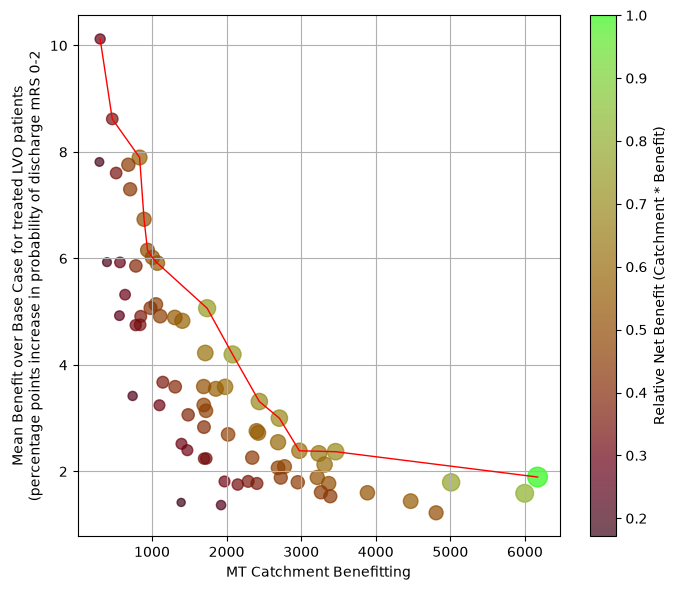

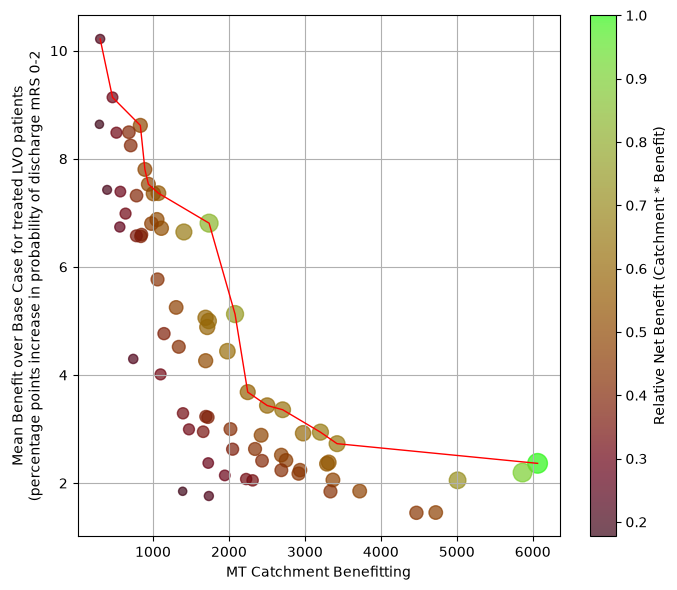

,Hospital Location,Admission Catchment Benefitting,Mean Benefit,Relative Benefit
0,Harrow,6169.9,0.01894,1.000
1,Smethwick,5997.0,0.01588,0.814
2,Watford,5010.6,0.01794,0.767
3,Stockport,1738.9,0.05065,0.752
4,Bournemouth,2080.5,0.04197,0.744


,Hospital Location,Admission Catchment Benefitting,Mean Benefit,Relative Benefit
0,Harrow,6063.9,0.02365,1.000
1,Smethwick,5865.6,0.02195,0.899
3,Stockport,1738.9,0.06809,0.829
4,Bournemouth,2080.5,0.05127,0.747
2,Watford,5010.6,0.02051,0.715



_bias10min


,SSNAP name,Hospital_City,Hospital,Weighted Net Benefit,Admission Catchment benefitting,Mean Benefit for Those Benefitting,Relative Benefit,Weighted Net Benefit (0!67 transferred),Admission Catchment benefitting (0!67 transferred),Mean Benefit for Those Benefitting (0!67 transferred),Relative Benefit (0!67 transferred)
0,Frimley Park Hospital,Frimley Park,GU167UJ,0.00131,2655.5,0.04482,1.000,0.00157,2655.5,0.05322,1.000
1,Luton and Dunstable Hospital,Luton and Dunstable,LU40DZ,0.00128,3853.5,0.03005,0.977,0.00149,3853.5,0.03492,0.949
2,Northwick Park Hospital HASU,Harrow,HA13UJ,0.00126,5958.8,0.01927,0.962,0.00157,5868.0,0.02408,1.000


73


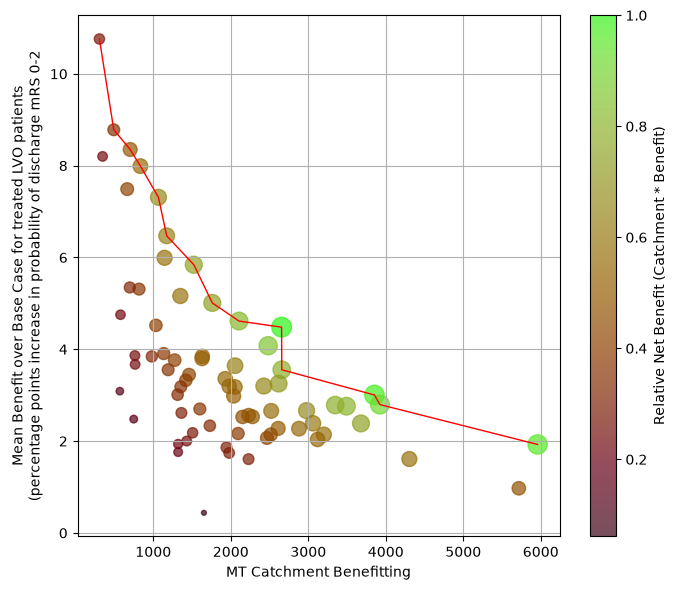

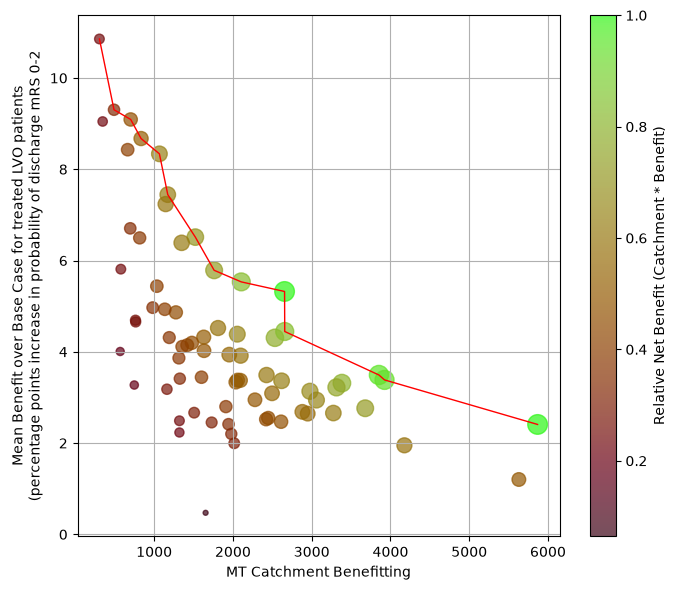

,Hospital Location,Admission Catchment Benefitting,Mean Benefit,Relative Benefit
0,Frimley Park,2655.5,0.04482,1.000
1,Luton and Dunstable,3853.5,0.03005,0.977
2,Harrow,5958.8,0.01927,0.962
3,Watford,3924.7,0.02795,0.916
4,Taunton,2482.1,0.04078,0.855


,Hospital Location,Admission Catchment Benefitting,Mean Benefit,Relative Benefit
0,Frimley Park,2655.5,0.05322,1.000
2,Harrow,5868.0,0.02408,1.000
1,Luton and Dunstable,3853.5,0.03492,0.949
3,Watford,3924.7,0.03384,0.936
7,Dartford,2657.6,0.04445,0.834


In [11]:
for s_bias in ['', '_bias10min']:
    print(s_bias)
    # Load data for scenario results:
    p = os.path.join(dir_output, file_unit_benefit + s_bias + '.csv')
    results_df = pd.read_csv(p)
    
    display(results_df.head(3))
    print(len(results_df))
    

    for s in ['', ' (0!67 transferred)']:
        s_str = '' if len(s) == 0 else s.replace(' ', '_')
        f = file_pareto_plot + s_bias + s_str + '.png'
        savename = os.path.join(dir_images, f)
        x, y, sizes, pareto_front = calculate_data_for_plot(results_df, s)
        make_scatter_plot(x, y, results_df, pareto_front, savename, show=True)

    # Make tables:
    rename_cols = {
        'Hospital_City': 'Hospital Location',
        'Admission Catchment benefitting': 'Admission Catchment Benefitting',
        'Mean Benefit for Those Benefitting': 'Mean Benefit',
        'Relative Benefit': 'Relative Benefit'
    }
    
    df = results_df[rename_cols.keys()].rename(columns=rename_cols)
    display(df.head())

    f = file_table_benefit + s_bias + '.csv'
    p = os.path.join(dir_output, dir_tables, f)
    df.to_csv(p, index=False)
    
    rename_cols = {
        'Hospital_City': 'Hospital Location',
        'Admission Catchment benefitting (0!67 transferred)':
            'Admission Catchment Benefitting',
        'Mean Benefit for Those Benefitting (0!67 transferred)':
            'Mean Benefit',
        'Relative Benefit (0!67 transferred)': 'Relative Benefit'
    }
    
    df = results_df[rename_cols.keys()].rename(columns=rename_cols)
    df = df.sort_values('Relative Benefit', ascending=False)
    display(df.head())

    f = file_table_benefit_lossy + s_bias + '.csv'
    p = os.path.join(dir_output, dir_tables, f)
    df.to_csv(p, index=False)
    print('')